# Laboratorio 08: Red neuronal desde cero

**Mateo Caballero** - Aprendizaje Estadístico - semestre 2026-2

Enunciado original: `semestre2026-2/Laboratorios/Laboratorio_08_nn_zeroV1.ipynb`

Cada bloque empieza con el enunciado original, copiado sin cambios, y debajo va el desarrollo de cada
punto. El problema es clasificar imágenes de $64\times64$ píxeles RGB en gato ($y=1$) o
no gato ($y=0$) con una red neuronal densa escrita solo con NumPy: propagación hacia adelante,
función de coste, propagación hacia atrás y descenso de gradiente.

In [1]:
import io
import time
import urllib.request

import numpy as np
import h5py
import matplotlib.pyplot as plt

SEED = 1

## 0. Datos

El enunciado descarga los dos archivos `.h5` al disco. Aquí se leen directamente en memoria
(`io.BytesIO`), de modo que el notebook funciona igual en Colab y en local y no deja archivos de datos
en la carpeta de entrega. Los nombres de las variables son los del enunciado.

In [2]:
base_url = ("https://raw.githubusercontent.com/CienciaDatosUdea/002_EstudiantesAprendizajeEstadistico/"
            "main/semestre2026-2/Laboratorios/datasets/cat_not_cat/")

def leer_h5(nombre):
    with urllib.request.urlopen(base_url + nombre) as respuesta:
        return h5py.File(io.BytesIO(respuesta.read()), "r")

train_dataset = leer_h5("train_catvnoncat.h5")
test_dataset = leer_h5("test_catvnoncat.h5")
print(train_dataset.keys())
print(test_dataset.keys())

<KeysViewHDF5 ['list_classes', 'train_set_x', 'train_set_y']>
<KeysViewHDF5 ['list_classes', 'test_set_x', 'test_set_y']>


In [3]:
# Read the data ([:] convierte cada dataset de h5py en un arreglo de NumPy)
xtrain_classes, xtrain, train_label = (train_dataset["list_classes"][:], train_dataset["train_set_x"][:],
                                       train_dataset["train_set_y"][:])
test_classes, xtest, test_label = (test_dataset["list_classes"][:], test_dataset["test_set_x"][:],
                                   test_dataset["test_set_y"][:])

print("Clases:", [c.decode() for c in xtrain_classes], "-> etiqueta 0 y 1")
print("xtrain:", xtrain.shape, xtrain.dtype, "  valores en", (xtrain.min(), xtrain.max()))
print("xtest: ", xtest.shape, xtest.dtype)
print(f"Gatos en train: {train_label.sum()} de {len(train_label)} ({train_label.mean():.1%})")
print(f"Gatos en test:  {test_label.sum()} de {len(test_label)} ({test_label.mean():.1%})")

Clases: ['non-cat', 'cat'] -> etiqueta 0 y 1
xtrain: (209, 64, 64, 3) uint8   valores en (np.uint8(0), np.uint8(255))
xtest:  (50, 64, 64, 3) uint8
Gatos en train: 72 de 209 (34.4%)
Gatos en test:  33 de 50 (66.0%)


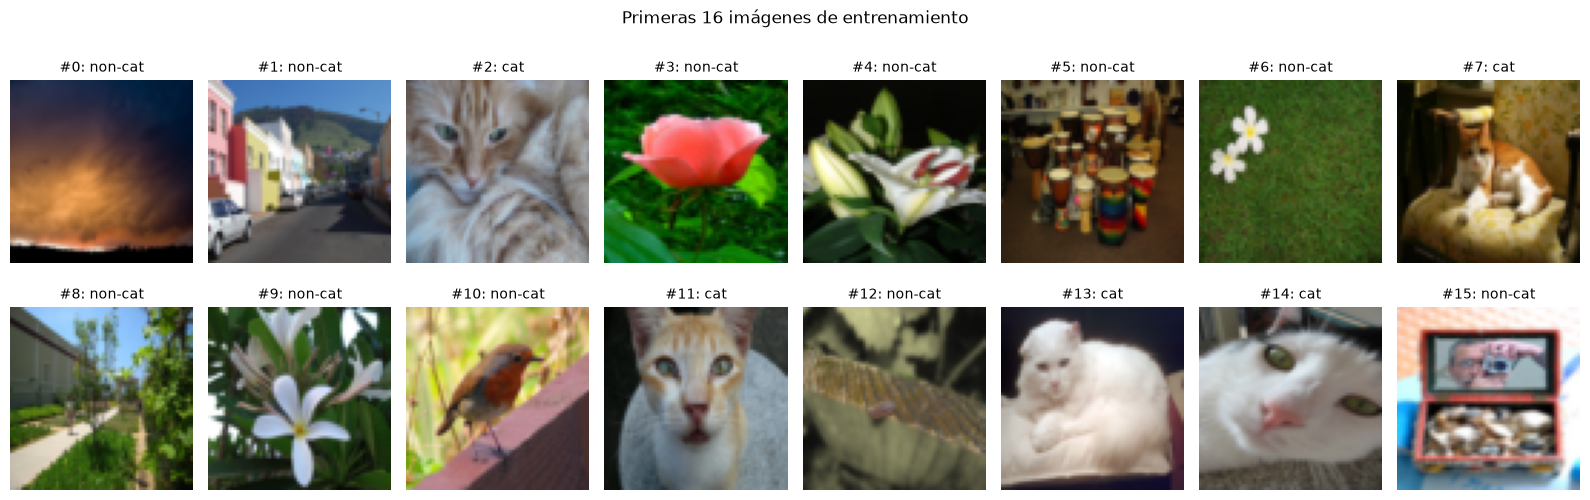

In [4]:
fig, axes = plt.subplots(2, 8, figsize=(16, 5.4))
for ax, i in zip(axes.ravel(), range(16)):
    ax.imshow(xtrain[i])
    ax.set_title(f"#{i}: {xtrain_classes[train_label[i]].decode()}", fontsize=10)
    ax.axis("off")
plt.suptitle("Primeras 16 imágenes de entrenamiento")
plt.tight_layout()
plt.show()

In [5]:
# Clasificadores triviales: sirven de referencia para juzgar la exactitud de la red
for nombre, constante in [("siempre 'no gato' (clase mayoritaria de train)", 0), ("siempre 'gato'", 1)]:
    print(f"{nombre:48s} train = {np.mean(train_label == constante):.3f}   "
          f"test = {np.mean(test_label == constante):.3f}")

siempre 'no gato' (clase mayoritaria de train)   train = 0.656   test = 0.340
siempre 'gato'                                   train = 0.344   test = 0.660


Las clases están invertidas entre entrenamiento y prueba: en train hay 72 gatos de 209 (34.4 %) y en test
33 de 50 (66 %). Eso cambia cómo hay que leer la exactitud:

- El clasificador trivial que predice siempre la clase mayoritaria de train ("no gato") acierta 65.6 % en
  train, pero solo 34 % en test.
- El que predice siempre "gato" acierta 66 % en test. Ese 66 % (y no el 50 %) es la referencia mínima que
  debe superar un modelo en el conjunto de prueba.

### Aplanar y normalizar

Cada imagen $64\times64\times3$ se convierte en un vector de $n_x = 12\,288$ entradas y se divide entre
255 para llevar los píxeles a $[0, 1]$ (código del enunciado). Luego se transpone para que **cada
columna sea una observación**, que es la convención de las ecuaciones: $A^{[0]}$ tiene forma
$n_x \times m$.

In [6]:
xtrain_ = np.reshape(xtrain, (209, 64*64*3)) / 255
xtest_ = np.reshape(xtest, (50, 64*64*3)) / 255

# El aplanado es reversible: la fila 0 vuelve a ser exactamente la imagen 0
assert np.allclose(np.reshape(xtrain_[0] * 255, (64, 64, 3)), xtrain[0])

A0, A0_test = xtrain_.T, xtest_.T
Y_train, Y_test = train_label.reshape(1, -1), test_label.reshape(1, -1)
print("A0:", A0.shape, " Y_train:", Y_train.shape)
print("A0_test:", A0_test.shape, " Y_test:", Y_test.shape)
print("Rango de A0:", (A0.min(), A0.max()))

A0: (12288, 209)  Y_train: (1, 209)
A0_test: (12288, 50)  Y_test: (1, 50)
Rango de A0: (np.float64(0.0), np.float64(1.0))


## 1. Topología de la red

> **Enunciado**
>
> Construyamos una red neuronal con una capa de entrada, una capa de salida con una red y L-1 redes ocultas.
> 
> # Con m datos de entrenamientos.
> 
> Para $m$ datos de entrenamiento, las expresión anteriores pueden ser resumidas en las siguientes ecuaciones
> 
> 
> 
> \begin{equation}
> \begin{bmatrix}
> z_1^{(0)}  &z_1^{(1)} & .&.& .&z_1^{(m)}\\
> z_2^{(0)}  &z_2^{(1)} &. &.&  .&z_2^{(m)}\\
> .          & .        &. & &   &.      \\
> .          & .        &  &. &   &.      \\
> .          & .        &  &  & .&      \\
> z_{n^{[l]}}^{(0)}&z_{n^{[l]}}^{(1)} & . & .& .& z_{n^{[l]}}^{(m)}        \\
> \end{bmatrix}^{[l]}=
> \begin{bmatrix}
> \theta_{11} & \theta_{12} & . & .& .& \theta_{1n^{[l-1]}}\\
> \theta_{21} & \theta_{22} & . & .& .& \theta_{2n^{[l-1]}}\\
> . & .  & . &   & & .\\
> . & .  &   & . & & .\\
> . & .  &   &  & .& .\\
> \theta_{n^{[l]}1} & \theta_{n^{[l]}2} & . & .& .& \theta_{n^{[l]}n^{[l-1]}}\\
> \end{bmatrix}^{[l]}_{n^{[l]} \times n^{[l-1]}}
> \begin{bmatrix}
> a_1^{(0)}  &a_1^{(1)} & .&.& .&a_1^{(m)}\\
> a_2^{(0)}  &a_2^{(1)} &. &.&  .&a_2^{(m)}\\
> .          & .        &. & &   &.      \\
> .          & .        &  &. &   &.      \\
> .          & .        &  &  & .&      \\
> a_{n^{[L-1]}}^{(0)}&a_{n^{[L-1]}}^{(1)} & . & .& .& a_{n^{[L-1]}}^{(m)}        \\
> \end{bmatrix}^{[l-1]} +
> \begin{bmatrix}
> b_1 \\
> b_2 \\
> . \\
> . \\
> . \\
> b_{n^{[l]}}\\
> \end{bmatrix}^{[l]}
> \end{equation}
> 
> 
> Escrito de una formas mas compacta tenemos que:
> 
> 
> \begin{equation}
> [ \vec{Z}^{[l](0)},\vec{Z}^{[l](1)},...,\vec{Z}^{[l](m)}  ]= \Theta^{[l]} [\vec{A}^{[l-1](0)},\vec{A}^{[l-1](1)},...,\vec{A}^{[l-1](m)} ]+ \vec{b}^{[l]}
> \end{equation}
> 
> Aplicando la funcion de activación:
> 
> \begin{equation}
> [\vec{A}^{[l](0)},\vec{A}^{[l](1)},...,\vec{A}^{[l](m)} ]=f([\vec{Z}^{[l](0)},\vec{Z}^{[l](1)},...,\vec{Z}^{[l](m)}  ])
> \end{equation}
> 
> Las dimensiones de las expresiones anteriores, pueden ser resumidas en lo siguiente:
> 
> $\mathrm{dim(\vec{\cal{Z}}^{[l]})}=n^{[l]}\times m $
> 
> $\mathrm{dim(\vec{\Theta}^{[l]})}=n^{[l]}\times n^{[l-1]}$
> 
> $\mathrm{dim(\vec{\cal{A}}^{[l]})}=n^{[l-1]}\times m $
> 
> $\mathrm{dim(\vec{b}^{[l]})}=n^{[l]}$

> **Enunciado**
>
> ## Topología de la red.
> 
> 1. Construir un clase  que permita definir una red neuronal con la topología
> deseada y la función de activación para cada capa, para ello deberá construir una funcion Topology con el número de capas de la red neuronal :
> 
> Topology = [n_x, n_h1, n_h2, n_h3, ...,n_y]
> 
> En este caso:
> - $n^{[0]}=n_x$ seran los valores de entradas de la capa de entrada
> - $n^{[1]}=n_{h1}$ Primera capa oculta de la red neuronal
> - $n^{[2]}=n_{h2}$ Segunda capa oculta de la red neuronal
> 
> .
> 
> .
> 
> .
> 
> 
> - $n^{[l]}=n_{hl}$ Segunda capa oculta de la red neuronal
> .
> 
> .
> 
> .
> 
> - $n^{[L]}=n_{y}$ Segunda capa oculta de la red neuronal
> 
> donde
> 
> - $\mathrm{n_x}$: valores de entrada
> - $\mathrm{n_{h1}}$: hidden layer 1
> - $\mathrm{n_{h2}}$: hidden layer 2
> - $\mathrm{n_y}$: last layer
> 
> - $n^{[L]}=n_{y}$ Segunda capa oculta de la red neuronal
> 
> 
> También definir una lista con las funciones de activaciones para cada capa.
> 
> 
> activation=[None, relu, relu, relu, ...,sigmoid]
> 
>   
> 
> 
> a. Cada unas de las capas deberá tener los parámetros de inicialización de manera aleatoria:
> 
> 
> La matriz de parametros para cada capa debera tener:
> 
> 
> $\mathrm{dim(\vec{b}^{[l]})}=n^{[l]}$
> 
> $\mathrm{dim(\vec{\Theta}^{[l]})}=n^{[l]}\times n^{[l-1]}$
> 
> Lo anteriores parametros deberán estar en el constructor de la clase.
> 
> 
> b. Construya un metodo llamado output cuya salida serán los valores de Z y A
> 
> 
> $\mathrm{dim(\vec{\cal{A}}^{[l]})}=n^{[l-1]}\times m $
> 
> $\mathrm{dim(\vec{\cal{Z}}^{[l]})}=n^{[l]}\times m $.

> **Enunciado**
>
> Se sugiere para cada capa emplear programación orientada a objetos definida de la siguiente manera:
> 
> ```
> class layer_nn():
>   def __init__(self, act_fun, nlayer_present, nlayer_before):
>     self.theta = 2*np.random.random((nlayer_present, nlayer_before)) - 1
>     self.B = 2*np.random.random((nlayer_present,1)) - 1
>     self.act_fun = act_fun
> 
>   def output(self, Z, A):
>     self.Z = Z
>     self.A = A
> 
> 
> 
> def act_function(x, activation):
>   if activation=="sigmoid":
>     f = lambda x: 1/(1+np.exp(-x))
>     fp = f(x)*(1-f(x))
>     return f, fp
>   
>   elif activation == "tanh":
>     f = lambda x: np.tanh
>     return tanh
>   else :
>     return 0
> ```

### Punto 1. Clase `layer_nn`, funciones de activación y `Topology`

Se conserva la estructura sugerida (`layer_nn(act_fun, nlayer_present, nlayer_before)` con `theta`,
`B`, `act_fun` en el constructor y un método `output`), con estas correcciones a la función
`act_function` sugerida:

- La rama `tanh` define `f = lambda x: np.tanh` (que devuelve la función, no su valor) y luego
  retorna `tanh`, una variable que no existe: fallaría con `NameError`.
- Falta `relu`, que es justamente la activación de las capas ocultas en la lista
  `activation=[None, relu, relu, relu, ...,sigmoid]` del enunciado.
- Devolvía `f` como función pero `fp` ya evaluada en `x`. Aquí ambas son funciones de $Z$, porque
  $f'(Z)$ se necesita en el backpropagation, mucho después de construir la capa.
- La sigmoide se escribe como $\sigma(z) = \tfrac12\left(1+\tanh(z/2)\right)$, que es la misma función
  pero no produce desbordamiento en `np.exp(-z)` cuando $z$ es muy negativo.

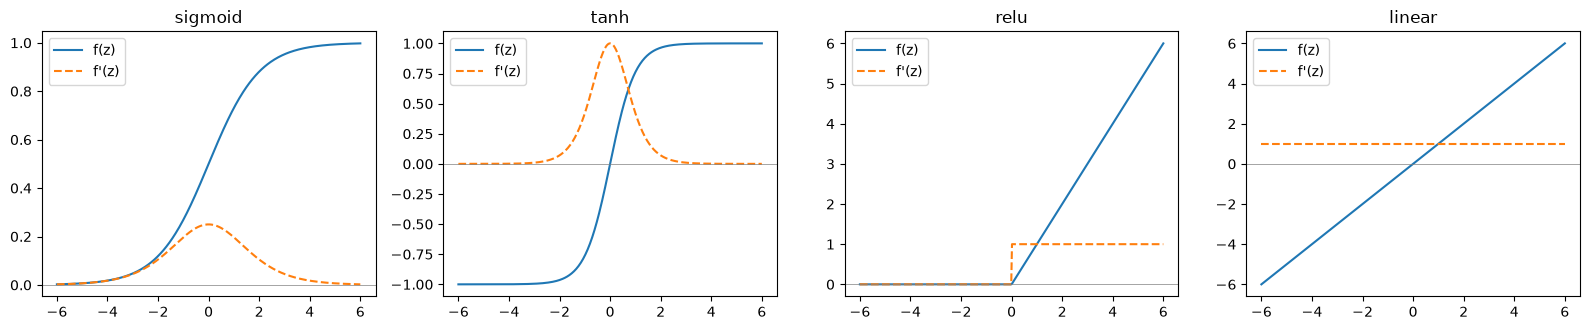

máx |sigma_estable - 1/(1+e^-z)| = 2.220446049250313e-16


In [7]:
def act_function(activation):
    """Devuelve (f, f'), ambas como funciones que se evalúan sobre Z."""
    if activation == "sigmoid":
        f = lambda z: 0.5 * (1 + np.tanh(z / 2))      # = 1 / (1 + exp(-z)), numéricamente estable
        fp = lambda z: f(z) * (1 - f(z))
    elif activation == "tanh":
        f = np.tanh
        fp = lambda z: 1 - np.tanh(z) ** 2
    elif activation == "relu":
        f = lambda z: np.maximum(0, z)
        fp = lambda z: (z > 0).astype(float)
    elif activation == "linear":
        f = lambda z: z
        fp = lambda z: np.ones_like(z)
    else:
        raise ValueError(f"Activación desconocida: {activation}")
    return f, fp


z = np.linspace(-6, 6, 400)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, nombre in zip(axes, ["sigmoid", "tanh", "relu", "linear"]):
    f, fp = act_function(nombre)
    ax.plot(z, f(z), label="f(z)")
    ax.plot(z, fp(z), "--", label="f'(z)")
    ax.set_title(nombre)
    ax.axhline(0, color="gray", lw=0.5)
    ax.legend()
plt.tight_layout()
plt.show()

# Comprobación: la sigmoide estable coincide con la fórmula clásica
sig, _ = act_function("sigmoid")
print("máx |sigma_estable - 1/(1+e^-z)| =", np.abs(sig(z) - 1 / (1 + np.exp(-z))).max())

**a. Inicialización aleatoria.** La sugerida es $\Theta, b \sim U(-1, 1)$. Se implementa como opción
`init="uniforme"`, pero por defecto se usa `init="escalada"`, que también es aleatoria: pesos
$\mathcal N(0, \sigma^2)$ con $\sigma^2 = 2/n^{[l-1]}$ si la capa es `relu` (inicialización de He) y
$1/n^{[l-1]}$ si no (una versión simple de Xavier), y sesgos en cero. La razón se comprueba en la celda de inicializaciones más abajo: con
12 288 entradas, $U(-1,1)$ produce valores de $Z^{[1]}$ enormes.

**b. Método `output`.** Recibe $A^{[l-1]}$ (de forma $n^{[l-1]}\times m$, la matriz que el enunciado
llama $\mathcal A^{[l]}$, la que *entra* a la capa $l$) y devuelve $Z^{[l]}$ y $A^{[l]}$, ambas de forma
$n^{[l]}\times m$. Las tres quedan guardadas en la capa porque el backpropagation las usa.

In [8]:
class layer_nn():
    def __init__(self, act_fun, nlayer_present, nlayer_before, init="escalada", rng=None):
        rng = np.random.default_rng() if rng is None else rng
        if init == "uniforme":                                   # sugerida en el enunciado: U(-1, 1)
            self.theta = 2 * rng.random((nlayer_present, nlayer_before)) - 1
            self.B = 2 * rng.random((nlayer_present, 1)) - 1
        elif init == "escalada":                                 # He (relu) / Xavier (resto)
            escala = np.sqrt((2.0 if act_fun == "relu" else 1.0) / nlayer_before)
            self.theta = escala * rng.standard_normal((nlayer_present, nlayer_before))
            self.B = np.zeros((nlayer_present, 1))
        else:
            raise ValueError(f"Inicialización desconocida: {init}")
        self.act_fun = act_fun
        self.f, self.fp = act_function(act_fun)

    def output(self, A_prev):
        """Z = Theta A_prev + B,  A = f(Z). Guarda A_prev, Z y A para el backpropagation."""
        self.A_prev = A_prev
        self.Z = self.theta @ A_prev + self.B
        self.A = self.f(self.Z)
        return self.Z, self.A


def Topology(topology, activation, init="escalada", seed=SEED):
    """topology = [n_x, n_h1, ..., n_y];  activation = [None, f_1, ..., f_L] (la entrada no tiene activación)."""
    assert len(topology) == len(activation) and activation[0] is None
    rng = np.random.default_rng(seed)
    return [layer_nn(activation[l], topology[l], topology[l - 1], init, rng)
            for l in range(1, len(topology))]

In [9]:
topology = [A0.shape[0], 20, 7, 5, 1]
activation = [None, "relu", "relu", "relu", "sigmoid"]
nn_red = Topology(topology, activation)

print(f"{'capa':>4} {'act':>8} {'dim Theta':>12} {'dim b':>8} {'parámetros':>11}")
for l, capa in enumerate(nn_red, start=1):
    print(f"{l:>4} {capa.act_fun:>8} {str(capa.theta.shape):>12} {str(capa.B.shape):>8} "
          f"{capa.theta.size + capa.B.size:>11,}")
print("Total de parámetros:", f"{sum(c.theta.size + c.B.size for c in nn_red):,}")

capa      act    dim Theta    dim b  parámetros
   1     relu  (20, 12288)  (20, 1)     245,780
   2     relu      (7, 20)   (7, 1)         147
   3     relu       (5, 7)   (5, 1)          40
   4  sigmoid       (1, 5)   (1, 1)           6
Total de parámetros: 245,973


## 2. Propagación hacia adelante

> **Enunciado**
>
> 2. Construir un generalizacion de la red, en el que entrada el valor inicial
> y la red neuronal completa arroje la salida y la actualizacion de la red con los parametros deseados:
> 
>   ```
>   A, nn = forward_pass(A0, nn_red)
> 
>  ```

### Punto 2. `forward_pass`

Recorre las capas en orden aplicando $Z^{[l]} = \Theta^{[l]}A^{[l-1]} + b^{[l]}$ y
$A^{[l]} = f^{[l]}(Z^{[l]})$. NumPy suma el vector columna $b^{[l]}$ a las $m$ columnas
(*broadcasting*), que es la suma de $\vec b^{[l]}$ a cada columna en la ecuación matricial. La red
se devuelve con cada capa actualizada: su $Z$ y su $A$ quedan guardados.

In [10]:
def forward_pass(A0, nn_red):
    A = A0
    for capa in nn_red:
        _, A = capa.output(A)
    return A, nn_red


A, nn_red = forward_pass(A0, nn_red)
for l, capa in enumerate(nn_red, start=1):
    print(f"capa {l}: A_prev {str(capa.A_prev.shape):>12} -> Z {str(capa.Z.shape):>10}, A {str(capa.A.shape):>10}")
print("Salida A^[L]:", A.shape, "  rango:", (A.min().round(3), A.max().round(3)))

capa 1: A_prev (12288, 209) -> Z  (20, 209), A  (20, 209)
capa 2: A_prev    (20, 209) -> Z   (7, 209), A   (7, 209)
capa 3: A_prev     (7, 209) -> Z   (5, 209), A   (5, 209)
capa 4: A_prev     (5, 209) -> Z   (1, 209), A   (1, 209)
Salida A^[L]: (1, 209)   rango: (np.float64(0.398), np.float64(0.582))


#### ¿Por qué no se usa por defecto la inicialización $U(-1,1)$?

Se compara la misma red con las dos inicializaciones en el primer paso hacia adelante. Para
$|z| > 10$, la derivada de la sigmoide es $\sigma'(z) < 5\times10^{-5}$: esa neurona está saturada
y casi no transmite gradiente.

In [11]:
_, sp = act_function("sigmoid")
print(f"sigma'(10) = {sp(10.0):.2e}\n")
for init in ["uniforme", "escalada"]:
    for acts in ([None, "sigmoid", "sigmoid", "sigmoid"], [None, "relu", "relu", "sigmoid"]):
        red = Topology([A0.shape[0], 10, 5, 1], acts, init=init)
        AL, red = forward_pass(A0, red)
        Z1 = red[0].Z
        print(f"{init:>9} {str(acts[1:]):>34}:  mediana |Z1| = {np.median(np.abs(Z1)):7.2f}   "
              f"|Z1| > 10: {np.mean(np.abs(Z1) > 10):5.1%}   máx |Z^[L]| = {np.abs(red[-1].Z).max():9.2f}")

sigma'(10) = 4.54e-05

 uniforme  ['sigmoid', 'sigmoid', 'sigmoid']:  mediana |Z1| =   15.27   |Z1| > 10: 65.2%   máx |Z^[L]| =      1.02


 uniforme        ['relu', 'relu', 'sigmoid']:  mediana |Z1| =   15.27   |Z1| > 10: 65.2%   máx |Z^[L]| =     76.40


 escalada  ['sigmoid', 'sigmoid', 'sigmoid']:  mediana |Z1| =    0.30   |Z1| > 10:  0.0%   máx |Z^[L]| =      1.09


 escalada        ['relu', 'relu', 'sigmoid']:  mediana |Z1| =    0.42   |Z1| > 10:  0.0%   máx |Z^[L]| =      1.67


- Con $U(-1,1)$ la mediana de $|Z^{[1]}|$ es 15.27 y el 65.2 % de los valores supera 10. Con sigmoide en la
  primera capa, casi dos tercios de las activaciones nacen saturadas y dejan pasar muy poco gradiente. La
  causa es la escala: $Z^{[1]}$ suma 12 288 productos $\theta_j x_j$ con pesos independientes de media
  cero, así que su varianza crece con $n_x$.
- Con relu el efecto llega hasta la salida: $|Z^{[L]}|$ alcanza 76.4, es decir, $a^{[L]}$ es prácticamente 0
  o 1 desde el inicio y la red arranca haciendo predicciones extremas.
- Con la inicialización escalada, la mediana de $|Z^{[1]}|$ queda entre 0.30 y 0.42 y ningún valor pasa de
  10. Dividir la varianza de los pesos entre $n^{[l-1]}$ compensa ese crecimiento.

Por eso el resto del laboratorio usa la inicialización escalada. La $U(-1,1)$ se retoma en las
configuraciones E y G de la sección 5, para ver su efecto en el entrenamiento.

## 3. Función de coste

> **Enunciado**
>
> 3. Encontrar la funcion de coste.
> 
> 
> $$-\frac{1}{m} \sum\limits_{i = 1}^{m} (y^{(i)}\log\left(a^{[L] (i)}\right) + (1-y^{(i)})\log\left(1- a^{[L](i)}\right)) \tag{7}$$

### Punto 3. Entropía cruzada binaria

Se implementa la ecuación (7). Si una predicción llega a ser exactamente 0 o 1, aparece $\log 0$.
Por eso $a^{[L]}$ se recorta a $[\varepsilon, 1-\varepsilon]$ con $\varepsilon = 10^{-12}$; eso no
cambia el valor del coste en ningún caso razonable.

In [12]:
def cost_function(AL, Y, eps=1e-12):
    m = Y.shape[1]
    AL = np.clip(AL, eps, 1 - eps)
    return -np.sum(Y * np.log(AL) + (1 - Y) * np.log(1 - AL)) / m


# Comprobaciones con casos de valor conocido
print("Predicción 0.5 para todos  ->", cost_function(np.full_like(Y_train, 0.5, dtype=float), Y_train),
      " (debe ser ln 2 =", np.log(2), ")")
print("Predicción perfecta        ->", cost_function(Y_train.astype(float), Y_train))
print("Predicción invertida       ->", cost_function(1.0 - Y_train, Y_train), " (= -ln(1e-12))")

nn_red = Topology(topology, activation)
AL, nn_red = forward_pass(A0, nn_red)
print("\nCoste de la red recién inicializada:", cost_function(AL, Y_train))

Predicción 0.5 para todos  -> 0.6931471805599453  (debe ser ln 2 = 0.6931471805599453 )
Predicción perfecta        -> 9.99977878280379e-13
Predicción invertida       -> 27.631035616929406  (= -ln(1e-12))



Coste de la red recién inicializada: 0.6911328019784408


Las tres comprobaciones dan lo esperado: $\ln 2 = 0.6931$ cuando la red responde 0.5 para todo, casi 0 con
la predicción perfecta y $-\ln\varepsilon \approx 27.6$ (el máximo que permite el recorte) con la predicción
invertida.

La red recién inicializada tiene coste 0.6911, muy cerca de $\ln 2$. Es lo que se espera: es la misma red
del punto 2 (misma topología y semilla), cuyas salidas estaban entre 0.398 y 0.582, cerca de 0.5. Una red
sin entrenar no debe estar segura de nada.

## 4. Propagación hacia atrás

> **Enunciado**
>
> 4. Construir un codigo que permita realizar el BackwardPropagation
> 
> 
> # Backward Propagation
> 
> Para una capa $l$ arbitraria tenemos que:
> 
> - \begin{equation}
> d\Theta^{[l]} =  d{\cal Z}^{(i)[l]} Trans(A)^{(i)[l-1]} = dA^{(i)[l]} f'({\cal Z}^{(i)[l]} ) Trans(A)^{(i)[l-1]}
> \end{equation}
> 
> - \begin{equation}
> db^{[l]} =  d{\cal Z}^{(i)[L]}  = dA^{(i)[l]} f'({\cal Z}^{(i)[l]} )
> \end{equation}
> ```
> db_L =  m_*np.sum(dZ, axis=1, keepdims=True)
> ```
> Los valores de dA pueden ser escritos como:
> - \begin{equation}
> dA^{(i)[l-1]} = \Theta^{l} \cdot dZ^{(i)[l]}
> \end{equation}
> 
> 
> 
> 
> 
> $ dZ^{[l]} = dA^{[l]} * f'^{[l]} (Z^{[l]}) $
> $ d\Theta^{[l]} = \frac{\partial \mathcal{J} }{\partial \Theta^{[l]}} = \frac{1}{m} dZ^{[l]} A^{[l-1] T} \tag{1}$
> $ db^{[l]} = \frac{\partial \mathcal{J} }{\partial b^{[l]}} = \frac{1}{m} \sum_{i = 1}^{m} dZ^{[l](i)}\tag{2}$
> $ dA^{[l-1]} = \frac{\partial \mathcal{L} }{\partial A^{[l-1]}} = \theta^{[l] T} dZ^{[l]} \tag{3}$
> 
> 
> Para la capa L esima:
> 
> ```
> dAL = -(np.divide(Y, A) - np.divide(1 - Y, 1 - A))
> ```

### Punto 4. `backward_pass`

Se parte de $dA^{[L]}$ (la derivada de la ecuación (7) respecto a $a^{[L]}$) y se recorre la red de la
última capa a la primera aplicando:

$$dZ^{[l]} = dA^{[l]} * f'^{[l]}(Z^{[l]}),\quad d\Theta^{[l]} = \tfrac1m dZ^{[l]}A^{[l-1]T},\quad
db^{[l]} = \tfrac1m\sum_i dZ^{[l](i)},\quad dA^{[l-1]} = \Theta^{[l]T}dZ^{[l]}.$$

Dos observaciones sobre el enunciado:

- En la expresión intermedia $dA^{(i)[l-1]} = \Theta^{l}\cdot dZ^{(i)[l]}$ falta la transpuesta. La
  ecuación (3) sí la tiene, y es necesaria por dimensiones: $\Theta^{[l]}$ es $n^{[l]}\times n^{[l-1]}$ y
  $dZ^{[l]}$ es $n^{[l]}\times m$, de modo que solo $\Theta^{[l]T}dZ^{[l]}$ da $n^{[l-1]}\times m$.
- El factor `m_` del fragmento `db_L = m_*np.sum(dZ, ...)` corresponde a $1/m$, como en la ecuación (2).

Los gradientes de cada capa quedan guardados en `capa.dtheta` y `capa.dB`.

In [13]:
def backward_pass(AL, Y, nn_red, eps=1e-12):
    m = Y.shape[1]
    AL = np.clip(AL, eps, 1 - eps)
    dA = -(np.divide(Y, AL) - np.divide(1 - Y, 1 - AL))          # dAL del enunciado
    for capa in reversed(nn_red):
        dZ = dA * capa.fp(capa.Z)                                  # dZ = dA * f'(Z)
        capa.dtheta = dZ @ capa.A_prev.T / m                       # (1)
        capa.dB = np.sum(dZ, axis=1, keepdims=True) / m            # (2)
        dA = capa.theta.T @ dZ                                     # (3)
    return nn_red

#### Verificación del gradiente (*gradient checking*)

Para comprobar que `backward_pass` es correcto se compara cada derivada con la diferencia centrada

$$\frac{\partial J}{\partial \theta} \approx \frac{J(\theta+\varepsilon) - J(\theta-\varepsilon)}{2\varepsilon},
\qquad \varepsilon = 10^{-6},$$

sobre una red pequeña con datos aleatorios (en la red real habría que evaluar el coste dos veces por
cada uno de sus cientos de miles de parámetros). El error relativo
$\lVert g_{\text{num}} - g_{\text{back}}\rVert / \lVert g_{\text{num}} + g_{\text{back}}\rVert$ debe ser del
orden de $10^{-7}$ o menor.

In [14]:
def gradient_check(topology, activation, m=8, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    X = rng.standard_normal((topology[0], m))
    Y = (rng.random((1, m)) > 0.5).astype(float)
    red = Topology(topology, activation, seed=seed)
    AL, red = forward_pass(X, red)
    backward_pass(AL, Y, red)
    g_num, g_back = [], []
    for capa in red:
        for P, G in ((capa.theta, capa.dtheta), (capa.B, capa.dB)):
            for idx in np.ndindex(P.shape):
                original = P[idx]
                P[idx] = original + eps
                J_mas = cost_function(forward_pass(X, red)[0], Y)
                P[idx] = original - eps
                J_menos = cost_function(forward_pass(X, red)[0], Y)
                P[idx] = original
                g_num.append((J_mas - J_menos) / (2 * eps))
                g_back.append(G[idx])
    g_num, g_back = np.array(g_num), np.array(g_back)
    return len(g_num), np.linalg.norm(g_num - g_back) / np.linalg.norm(g_num + g_back)


for acts in ([None, "relu", "tanh", "sigmoid"], [None, "sigmoid", "sigmoid", "sigmoid"],
             [None, "linear", "relu", "sigmoid"]):
    n, err = gradient_check([5, 4, 3, 1], acts)
    print(f"{str(acts[1:]):34s} {n} parámetros   error relativo = {err:.2e}")

['relu', 'tanh', 'sigmoid']        43 parámetros   error relativo = 2.12e-09
['sigmoid', 'sigmoid', 'sigmoid']  43 parámetros   error relativo = 2.81e-09
['linear', 'relu', 'sigmoid']      43 parámetros   error relativo = 1.08e-09


In [15]:
# Con salida sigmoide y entropía cruzada, dZ^[L] = dA^[L] * sigma'(Z^[L]) se simplifica a A^[L] - Y
nn_red = Topology(topology, activation)
AL, nn_red = forward_pass(A0, nn_red)
dAL = -(Y_train / AL - (1 - Y_train) / (1 - AL))
dZL = dAL * nn_red[-1].fp(nn_red[-1].Z)
print("máx |dZ^[L] - (A^[L] - Y)| =", np.abs(dZL - (AL - Y_train)).max())

máx |dZ^[L] - (A^[L] - Y)| = 1.1102230246251565e-16


- El *gradient checking* da errores relativos de $2.1\times10^{-9}$, $2.8\times10^{-9}$ y $1.1\times10^{-9}$
  con tres combinaciones de activaciones que cubren relu, tanh, sigmoid y lineal, muy por debajo de
  $10^{-7}$. Con eso, `backward_pass` es correcto para esos casos. La prueba se hizo en una red pequeña
  (43 parámetros); en la red real no se repite porque habría que evaluar el coste dos veces por cada uno de
  sus cientos de miles de parámetros.
- La segunda celda comprueba que, con salida sigmoide y entropía cruzada, aplicar la regla general a la
  última capa da exactamente $dZ^{[L]} = A^{[L]} - Y$ (diferencia máxima de $10^{-16}$, error de
  redondeo).

## 5. Descenso de gradiente y entrenamiento

> **Enunciado**
>
> # Aplicacion gradiente descendente
> 
> $$ \Theta^{[l]} = \Theta^{[l]} - \alpha \text{ } d\Theta^{[l]} \tag{16}$$
> $$ b^{[l]} = b^{[l]} - \alpha \text{ } db^{[l]} \tag{17}$$

### Aplicación del descenso de gradiente

`update_parameters` aplica las ecuaciones (16) y (17) a todas las capas, y `train` repite el ciclo
*forward → coste → backward → actualización* con todas las imágenes de entrenamiento en cada
iteración (descenso de gradiente por lotes completos). La clase predicha es 1 (gato) si
$a^{[L]} > 0.5$.

In [16]:
def update_parameters(nn_red, alpha):
    for capa in nn_red:
        capa.theta -= alpha * capa.dtheta       # (16)
        capa.B -= alpha * capa.dB               # (17)
    return nn_red


def train(A0, Y, topology, activation, alpha, n_iter, init="escalada", seed=SEED):
    nn_red = Topology(topology, activation, init=init, seed=seed)
    costos = []
    for _ in range(n_iter):
        AL, nn_red = forward_pass(A0, nn_red)
        costos.append(cost_function(AL, Y))
        nn_red = backward_pass(AL, Y, nn_red)
        nn_red = update_parameters(nn_red, alpha)
    return nn_red, np.array(costos)


def predict(A0, nn_red):
    AL, _ = forward_pass(A0, nn_red)
    return (AL > 0.5).astype(int), AL


def accuracy(A0, Y, nn_red):
    return np.mean(predict(A0, nn_red)[0] == Y)

#### Comparación de configuraciones

Se entrenan siete redes con la misma tasa $\alpha = 0.0075$ y 2 500 iteraciones:

| Config. | Topología | Activaciones | Inicialización | Qué se quiere ver |
|---|---|---|---|---|
| A | `[12288, 1]` | sigmoid | escalada | Sin capas ocultas: es una regresión logística, la referencia |
| B | `[12288, 7, 1]` | relu, sigmoid | escalada | Una capa oculta |
| C | `[12288, 20, 7, 5, 1]` | relu ×3, sigmoid | escalada | La forma `[None, relu, relu, relu, sigmoid]` del enunciado |
| D | `[12288, 10, 5, 1]` | sigmoid ×3 | escalada | Capas ocultas sigmoides |
| E | `[12288, 10, 5, 1]` | sigmoid ×3 | uniforme $U(-1,1)$ | D con la inicialización sugerida |
| F | `[12288, 10, 5, 1]` | relu, relu, sigmoid | escalada | D cambiando solo la activación (control) |
| G | `[12288, 20, 7, 5, 1]` | relu ×3, sigmoid | uniforme $U(-1,1)$ | C cambiando solo la inicialización (control) |

D y C difieren en la activación y también en el tamaño, así que comparar solo esas dos no permite atribuir
la diferencia a la activación. F y G son los controles: cada una cambia un único factor respecto de D y de C.

La red de referencia del laboratorio es C, fijada de antemano porque es la que describe el
enunciado. Este laboratorio no tiene conjunto de validación (solo 209 imágenes de entrenamiento),
así que el test no se usa para escoger entre configuraciones: se reporta para todas y se
interpreta con la incertidumbre que corresponde a 50 imágenes.

In [17]:
configs = {
    "A": ([A0.shape[0], 1], [None, "sigmoid"], "escalada"),
    "B": ([A0.shape[0], 7, 1], [None, "relu", "sigmoid"], "escalada"),
    "C": ([A0.shape[0], 20, 7, 5, 1], [None, "relu", "relu", "relu", "sigmoid"], "escalada"),
    "D": ([A0.shape[0], 10, 5, 1], [None, "sigmoid", "sigmoid", "sigmoid"], "escalada"),
    "E": ([A0.shape[0], 10, 5, 1], [None, "sigmoid", "sigmoid", "sigmoid"], "uniforme"),
    "F": ([A0.shape[0], 10, 5, 1], [None, "relu", "relu", "sigmoid"], "escalada"),
    "G": ([A0.shape[0], 20, 7, 5, 1], [None, "relu", "relu", "relu", "sigmoid"], "uniforme"),
}
alpha, n_iter = 0.0075, 2500

redes, historias, filas = {}, {}, []
for nombre, (top, acts, init) in configs.items():
    t0 = time.time()
    redes[nombre], historias[nombre] = train(A0, Y_train, top, acts, alpha, n_iter, init=init)
    filas.append((nombre, sum(c.theta.size + c.B.size for c in redes[nombre]), historias[nombre][0],
                  historias[nombre][-1], accuracy(A0, Y_train, redes[nombre]),
                  accuracy(A0_test, Y_test, redes[nombre]), time.time() - t0))

print(f"{'cfg':>3} {'parámetros':>11} {'coste ini':>10} {'coste fin':>10} {'acc train':>10} {'acc test':>9} {'tiempo':>8}")
for f in filas:
    print(f"{f[0]:>3} {f[1]:>11,} {f[2]:>10.4f} {f[3]:>10.4f} {f[4]:>10.3f} {f[5]:>9.3f} {f[6]:>7.1f}s")

cfg  parámetros  coste ini  coste fin  acc train  acc test   tiempo
  A      12,289     0.6609     0.0788      0.995     0.700    23.9s
  B      86,031     0.6954     0.0193      0.995     0.740    20.9s
  C     245,973     0.6911     0.0024      1.000     0.740    24.0s
  D     122,951     0.6614     0.5874      0.656     0.340    18.5s
  E     122,951     0.8592     0.6294      0.656     0.340    19.1s
  F     122,951     0.6677     0.0834      0.995     0.620    18.2s
  G     245,973    11.9262     0.5076      0.703     0.440    25.7s


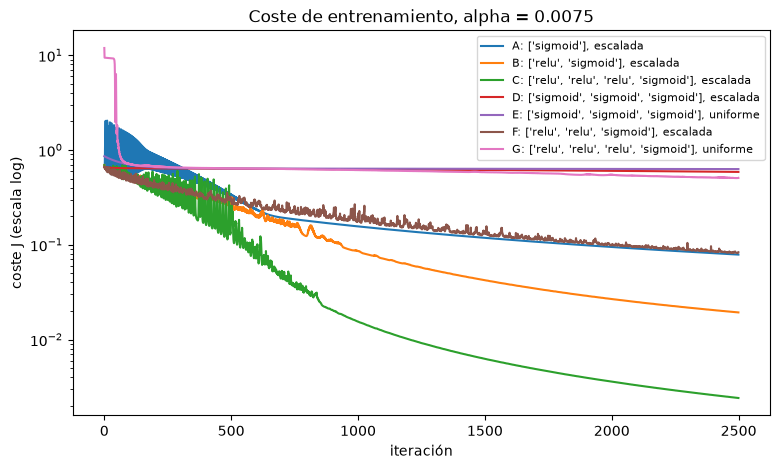

In [18]:
fig, ax = plt.subplots(figsize=(9, 5))
for nombre, costos in historias.items():
    ax.plot(costos, label=f"{nombre}: {configs[nombre][1][1:]}, {configs[nombre][2]}")
ax.set_yscale("log")
ax.set_xlabel("iteración")
ax.set_ylabel("coste J (escala log)")
ax.set_title(f"Coste de entrenamiento, alpha = {alpha}")
ax.legend(fontsize=8)
plt.show()

#### Tamaño del gradiente por capa

Se mide $\lVert d\Theta^{[l]}\rVert$ en la primera iteración (red recién inicializada) para las redes
C, D, F, E y G.

In [19]:
for nombre in ["C", "D", "F", "E", "G"]:
    top, acts, init = configs[nombre]
    red = Topology(top, acts, init=init)
    AL, red = forward_pass(A0, red)
    backward_pass(AL, Y_train, red)
    normas = "  ".join(f"capa {l}: {np.linalg.norm(c.dtheta):.1e}" for l, c in enumerate(red, start=1))
    print(f"{nombre}: {normas}")

C: capa 1: 2.7e+00  capa 2: 6.2e-02  capa 3: 4.5e-02  capa 4: 8.0e-02
D: capa 1: 2.7e-01  capa 2: 2.8e-02  capa 3: 1.2e-01
F: capa 1: 1.6e+00  capa 2: 5.7e-02  capa 3: 9.6e-02
E: capa 1: 9.5e-02  capa 2: 1.2e-01  capa 3: 4.9e-01
G: capa 1: 1.0e+01  capa 2: 7.9e+00  capa 3: 5.5e+01  capa 4: 8.0e+01


In [20]:
# ¿Qué predicen D, E y G al final? (proporción de imágenes clasificadas como gato)
for nombre in ["D", "E", "G"]:
    pred_tr, AL_tr = predict(A0, redes[nombre])
    pred_te, _ = predict(A0_test, redes[nombre])
    print(f"{nombre}: predice 'gato' en {pred_tr.mean():.1%} de train y {pred_te.mean():.1%} de test;  "
          f"a^[L] en train entre {AL_tr.min():.3f} y {AL_tr.max():.3f}")

# Referencia: coste de predecir siempre la proporción de gatos de train (sin mirar la imagen)
p_gato = Y_train.mean()
J_base = -(p_gato * np.log(p_gato) + (1 - p_gato) * np.log(1 - p_gato))
print(f"\nCoste de predecir siempre a = {p_gato:.3f}: {J_base:.4f}")
print("Coste por iteración:", "  ".join(f"{k:>6}" for k in [0, 500, 1000, 1500, 2000, 2499]))
for nombre in ["C", "D", "F", "E", "G"]:
    print(f"   {nombre}               ", "  ".join(f"{historias[nombre][k]:6.4f}" for k in [0, 500, 1000, 1500, 2000, 2499]))

D: predice 'gato' en 0.0% de train y 0.0% de test;  a^[L] en train entre 0.219 y 0.434
E: predice 'gato' en 0.0% de train y 0.0% de test;  a^[L] en train entre 0.283 y 0.441
G: predice 'gato' en 44.0% de train y 34.0% de test;  a^[L] en train entre 0.000 y 0.787

Coste de predecir siempre a = 0.344: 0.6440
Coste por iteración:      0     500    1000    1500    2000    2499
   C                0.6911  0.1885  0.0155  0.0063  0.0036  0.0024
   D                0.6614  0.6357  0.6262  0.6156  0.6031  0.5874
   F                0.6677  0.3045  0.1830  0.1383  0.0998  0.0834
   E                0.8592  0.6385  0.6353  0.6333  0.6314  0.6294
   G                11.9262  0.6394  0.6135  0.5831  0.5464  0.5076


- A, B y C aprenden, pero memorizan. Llegan a 99.5-100 % en train y se quedan en 70-74 % en test. Tienen
  entre 12 289 y 245 973 parámetros para solo 209 imágenes y no llevan regularización, así que es
  sobreajuste. El coste de C baja hasta 0.0024.
- Las diferencias entre A, B y C en test son pequeñas: B y C aciertan 37 de 50 imágenes y A acierta 35. Con 50
  imágenes, dos aciertos no bastan para decir que las capas ocultas mejoran la regresión logística (el
  error estándar de la exactitud de C es de 6 puntos, ver la celda siguiente).
- D y E no llegan a separar las clases en 2 500 iteraciones. Todas sus salidas quedan por debajo de 0.5, así
  que clasifican todo como "no gato" y su exactitud coincide con la del clasificador trivial (0.656 en
  train y 0.340 en test). Algo aprenden: sus costes finales (0.5874 y 0.6294) bajan del coste de predecir
  siempre la proporción de gatos (0.6440). Pero van mucho más lento que C, que a la iteración 1 000 ya está
  en 0.0155.

D se diferencia de C en la activación y también en el tamaño (`[10, 5]` frente a `[20, 7, 5]`), así que
la comparación directa no permite saber cuál de los dos factores pesa. Para eso están F y G, que cambian un
solo factor cada una:

- F es D con relu en las capas ocultas (misma topología, misma inicialización). Sí aprende: coste final de
  0.0834 y 99.5 % en train, frente a 0.5874 y 65.6 % de D. Con la misma topología, la activación cambia el
  resultado. En test F acierta 62 %, por debajo del 66 % del clasificador trivial: memoriza igual que A, B y C.
- G es C con la inicialización $U(-1,1)$. Su coste inicial es 11.93 (el de C es 0.6911) y en 2 500
  iteraciones solo llega a 0.5076, con 70.3 % en train y 44 % en test, lejos del 100 % y el 74 % de C. Con la
  misma activación, la inicialización también cambia el resultado: arruina un entrenamiento que con la
  inicialización escalada funcionaba.

Sobre el tamaño del gradiente en la primera iteración: la norma de $d\Theta^{[1]}$ es 2.7 en C, 0.27 en D, 1.6
en F, 0.095 en E y 10 en G. D y F (misma topología) difieren en un factor de unas 6 veces. Es coherente con
el desvanecimiento del gradiente en capas sigmoides: como $\sigma'(z) \le 1/4$, cada capa sigmoide multiplica
por a lo sumo 1/4 la señal que retrocede (sin contar el efecto de los pesos), mientras que relu la deja
pasar sin cambio donde $z>0$. Esa explicación
es teórica; no la comprobé aparte. En G las normas son muy grandes (hasta 80 en la última capa), coherente
con el coste inicial de 11.93.

Una observación más: las curvas de A y C oscilan con fuerza durante las primeras centenas de iteraciones y
luego bajan de forma suave; la de F sigue ruidosa casi hasta el final (figura). No investigué la causa. Todas las configuraciones usan la misma tasa
$\alpha = 0.0075$, y una tasa menor podría suavizarlas, pero no lo probé.

En resumen, con los mismos datos y la misma tasa importan la activación de las capas ocultas y la
inicialización, además de la topología, y los controles F y G lo comprueban cambiando cada factor por
separado.

#### Red de referencia (C) en el conjunto de prueba

Con 50 imágenes, cada acierto o fallo mueve la exactitud 2 puntos. Para tener una idea de esa
incertidumbre se calcula el error estándar binomial $\sqrt{p(1-p)/n}$ y un intervalo aproximado del
95 % ($p \pm 1.96\,\mathrm{EE}$).

In [21]:
red = redes["C"]
pred_test, prob_test = predict(A0_test, red)
p, n = np.mean(pred_test == Y_test), Y_test.shape[1]
ee = np.sqrt(p * (1 - p) / n)
print(f"Exactitud en test: {p:.3f}  (EE = {ee:.3f},  IC 95 % aprox. [{p - 1.96*ee:.3f}, {p + 1.96*ee:.3f}])")
print(f"Referencia trivial 'siempre gato' en test: {Y_test.mean():.3f}\n")

vp = int(np.sum((pred_test == 1) & (Y_test == 1)))
vn = int(np.sum((pred_test == 0) & (Y_test == 0)))
fp_ = int(np.sum((pred_test == 1) & (Y_test == 0)))
fn = int(np.sum((pred_test == 0) & (Y_test == 1)))
print("Matriz de confusión (test)")
print(f"{'':>16}{'pred. no gato':>15}{'pred. gato':>12}")
print(f"{'real no gato':>16}{vn:>15}{fp_:>12}")
print(f"{'real gato':>16}{fn:>15}{vp:>12}")
print(f"\nPrecisión (gato) = {vp/(vp+fp_):.3f}   Sensibilidad (gato) = {vp/(vp+fn):.3f}")

Exactitud en test: 0.740  (EE = 0.062,  IC 95 % aprox. [0.618, 0.862])
Referencia trivial 'siempre gato' en test: 0.660

Matriz de confusión (test)
                  pred. no gato  pred. gato
    real no gato             12           5
       real gato              8          25

Precisión (gato) = 0.833   Sensibilidad (gato) = 0.758


a^[L] de gatos predichos 'no gato': [0.    0.004 0.007 0.052 0.091 0.222 0.23  0.292]
a^[L] de 'no gatos' predichos gato: [0.662 0.81  0.881 0.997 1.   ]


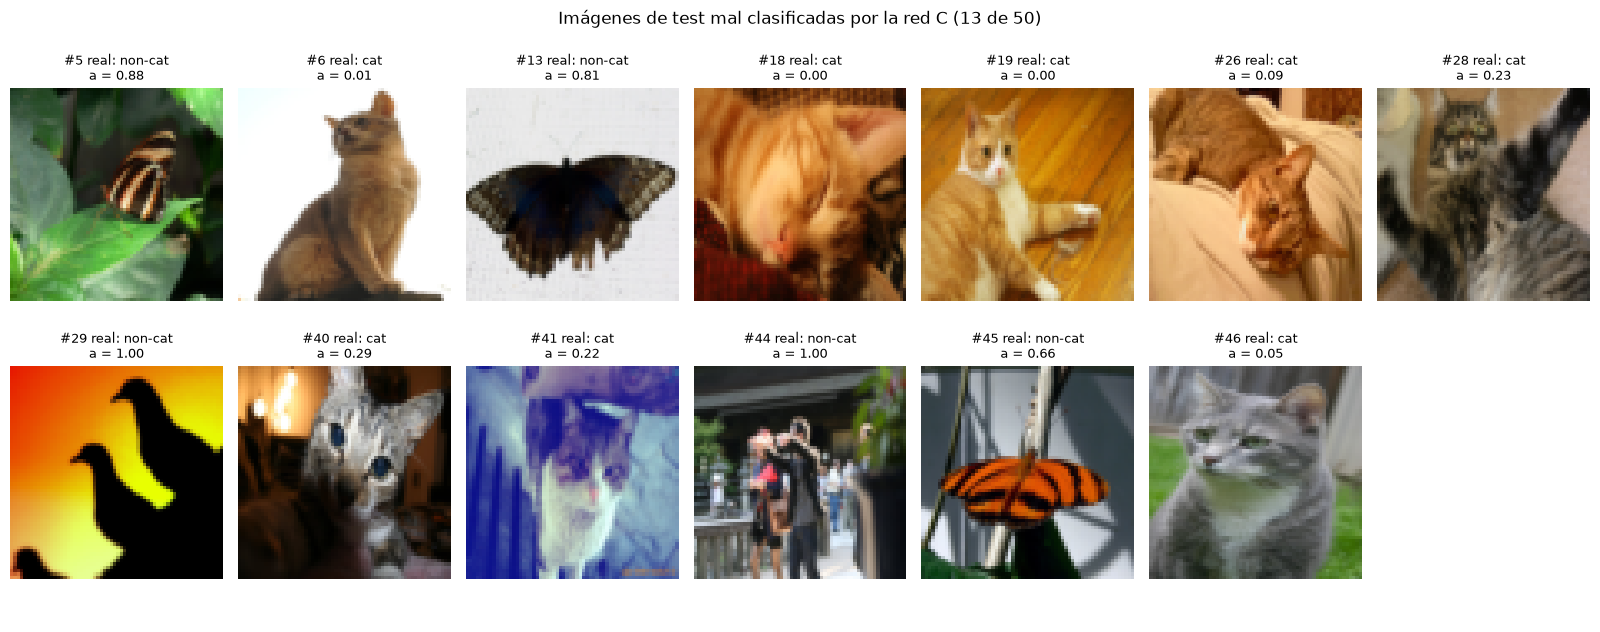

In [22]:
errores = np.where(pred_test[0] != Y_test[0])[0]
for etiqueta, real in [("gatos predichos 'no gato'", 1), ("'no gatos' predichos gato", 0)]:
    a = np.sort(prob_test[0, errores[Y_test[0, errores] == real]])
    print(f"a^[L] de {etiqueta}:", np.round(a, 3))

ncol = 7
nfil = int(np.ceil(len(errores) / ncol))
fig, axes = plt.subplots(nfil, ncol, figsize=(2.3 * ncol, 3.2 * nfil))
for ax in axes.ravel():
    ax.axis("off")
for ax, i in zip(axes.ravel(), errores):
    ax.imshow(xtest[i])
    ax.set_title(f"#{i} real: {test_classes[test_label[i]].decode()}\n"
                 f"a = {prob_test[0, i]:.2f}", fontsize=9)
plt.suptitle(f"Imágenes de test mal clasificadas por la red C ({len(errores)} de {n})")
plt.tight_layout()
plt.show()

- La red C acierta 37 de 50 imágenes (74 %). El intervalo aproximado del 95 % es [61.8 %, 86.2 %] y contiene el
  66 % del clasificador trivial "siempre gato". Con este conjunto de prueba no se puede afirmar que la red
  supere esa referencia; haría falta un test más grande.
- De los 13 errores, 8 son gatos clasificados como "no gato" (falsos negativos) y 5 son "no gatos"
  clasificados como gato. La precisión para la clase gato es 83.3 % (cuando dice "gato", casi siempre acierta)
  y la sensibilidad es 75.8 % (se le escapa uno de cada cuatro gatos). Que predominen los falsos negativos es
  coherente con que la red se entrenó con mayoría de "no gatos" (65.6 %), aunque con 13 errores no se puede
  separar ese efecto del azar.
- La salida $a^{[L]}$ de cada error aparece impresa y en el título de cada imagen. En 7 de los 13 errores la
  red se equivoca con mucha seguridad ($a^{[L]} < 0.1$ en cinco gatos y $a^{[L]} > 0.9$ en dos "no gatos"), otra
  señal de sobreajuste.
- En la figura, 3 de los 5 falsos positivos son mariposas. Entre los gatos no reconocidos hay primeros
  planos, gatos dormidos o en posturas poco habituales, y una imagen con los colores muy alterados (#41). Una
  red densa trata cada píxel como una entrada independiente y no tiene forma de reconocer la misma figura en
  otra posición o escala. Esa limitación es la que abordan las redes convolucionales.

## Conclusiones

1. **Implementación (puntos 1-4).** Se construyó con NumPy una red densa de topología arbitraria: la clase
   `layer_nn`, la función `Topology`, `forward_pass`, la entropía cruzada, `backward_pass` y el descenso de
   gradiente de las ecuaciones (16)-(17). El backpropagation se validó con *gradient checking* (errores
   relativos del orden de $10^{-9}$).
2. **Inicialización.** Con 12 288 entradas, la $U(-1,1)$ sugerida satura el 65 % de las activaciones de la
   primera capa. Aplicada a la red C (configuración G), sube el coste inicial de 0.69 a 11.9 y deja la
   exactitud de entrenamiento en 70 % en lugar de 100 %.
3. **Activaciones.** Con la misma topología, pasar las capas ocultas de sigmoide a relu (D → F) lleva el coste
   final de 0.5874 a 0.0834 y la exactitud de entrenamiento de 65.6 % a 99.5 % en 2 500 iteraciones. El
   gradiente de la primera capa es unas 6 veces mayor.
4. **Generalización.** Las redes que aprenden llegan a 99.5-100 % en train y a 62-74 % en test: sobreajustan,
   porque tienen hasta 246 000 parámetros para 209 imágenes. Además, el test tiene solo 50 imágenes y la
   proporción de clases opuesta a la del entrenamiento (66 % de gatos frente a 34 %). Por eso el 74 % de la red
   de referencia no se distingue estadísticamente del 66 % que se obtiene prediciendo siempre "gato".
5. **Posibles mejoras (no evaluadas aquí).** Regularización L2 o *dropout*, un conjunto de validación para
   elegir topología y tasa de aprendizaje, aumento de datos (por ejemplo, reflexiones horizontales) y redes
   convolucionales, que aprovechan la estructura espacial de la imagen (laboratorio 11).

#### Reproducibilidad

In [23]:
import sys
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| h5py", h5py.__version__)
print("Semilla de inicialización:", SEED)

Python 3.14.7 | numpy 2.5.3 | h5py 3.15.1
Semilla de inicialización: 1


Toda la aleatoriedad del notebook (pesos iniciales y datos sintéticos del *gradient checking*) sale de
generadores `np.random.default_rng` con semilla fija. Ejecutarlo de principio a fin reproduce las mismas
cifras; solo cambian los tiempos impresos. En CPU tarda unos 3 minutos en este equipo, casi todo en el
entrenamiento de las siete configuraciones.